In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa ejecuta la obra civil de una planta de generación en una zona de aves esteparias. La **declaración de impacto ambiental (DIA)** del proyecto, incorporada a la autorización, impone la condición siguiente: «no se realizarán desbroces, talas, movimientos de tierra ni voladuras entre el **1 de marzo** y el **31 de mayo**, periodo reproductor de las especies esteparias del área». El proyecto empieza el 1 de enero (semana 1), de modo que la ventana ocupa las **semanas 9 a 22**. El cuadro de prelaciones, las duraciones (semanas) y qué actividades están afectadas por la condición (`afeccion` = 1: desbroce, explanación, zanjas, cimentaciones con voladura) se adjuntan. El retraso de la entrega tiene una penalidad de 12 k€ por semana.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, afeccion
    ('A'     , '---'      , 6       , 1       ),
    ('B'     , '---'      , 3       , 0       ),
    ('C'     , 'A,B'      , 2       , 0       ),
    ('D'     , 'C'        , 2       , 0       ),
    ('E'     , 'C'        , 2       , 1       ),
    ('F'     , 'C'        , 3       , 0       ),
    ('G'     , 'D,F'      , 2       , 1       ),
    ('H'     , 'E,G'      , 1       , 0       ),
    ('I'     , 'F'        , 8       , 0       ),
], columns=['activity', 'predecessor', 'duration', 'afeccion']).set_index('activity')
datos_enunciado

,predecessor,duration,afeccion
activity,,,
A,---,6,1
B,---,3,0
C,"A,B",2,0
D,C,2,0
E,C,2,1
F,C,3,0
G,"D,F",2,1
H,"E,G",1,0
I,F,8,0


> **De: Director de obra**
> El cronograma va con inicios más tempranos y así se ha presentado. Los trabajos de E caen dentro de la ventana: los hacemos igual con un biólogo delante y, si aparece un nido, lo movemos. La ventana es una recomendación de la DIA, no está en el contrato con el cliente, y parar nos costaría 6 semanas, 72 k€ de penalidad.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S12 — Condiciones de la autorización como restricciones del cronograma.** Las condiciones de la declaración de impacto ambiental, de la licencia o de la ordenanza (ventanas biológicas, horarios de trabajo, límites de ruido) son parte del proyecto autorizado: entran en el cronograma como restricciones de fecha u horario de las actividades afectadas, no como riesgos que se aceptan ni como opciones de compresión. Qué actividades quedan afectadas lo decide el calendario, y una ventaja de plazo obtenida incumpliendo la condición no es una opción de la tabla; incumplirla es infracción. *(cf. Ley 21/2013, arts. 41 y 55.3.c); Ley 42/2007, art. 54.5; Ley 37/2003, arts. 6 y 28; PMBOK 8 §3.7.3 (dominio del cronograma: huella y uso de recursos en las decisiones de programación).)*
- **S11 — Riesgo de sostenibilidad.** Una amenaza ambiental, climática, regulatoria o social que puede cambiar el plazo, el coste o el resultado del proyecto es un riesgo del proyecto: entra en el registro con su probabilidad y su impacto y se cuantifica en el cronograma como cualquier otro. Dejarlo fuera «porque es el clima» o «porque es de la administración» es retener información (C4 de la lección 19). *(cf. PMBOK 8 §3.7.1 (riesgos de sostenibilidad) y §3.7.3 (dominio de desempeño del riesgo).)*
- **Norma o dato de referencia — la declaración de impacto ambiental fija las condiciones en que el proyecto puede ejecutarse (entre ellas, las medidas preventivas y correctoras y los calendarios de obra que protegen a la fauna en reproducción) y se incorpora a la autorización; incumplir esas condiciones es infracción grave. Con independencia de la DIA, está prohibido dañar, molestar o inquietar intencionadamente a los animales silvestres y destruir sus nidos, crías o huevos** *(Ley 21/2013, arts. 41 y 55.3.c); Ley 42/2007, art. 54.5.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Con el calendario de inicios más tempranos, identifique qué actividades afectadas terminan antes de la ventana y cuáles la ocupan (semanas dentro de la ventana) y, para estas, la espera necesaria para empezar después del 31 de mayo y si cabe en su holgura total. Obtenga el cronograma con las esperas (recalculando el calendario después de cada una) y la duración del proyecto.  "
pregunta_2 = "2. (A) Calcule el retraso y la penalidad del plan con esperas. Obtenga el adelanto mínimo del inicio del proyecto con el que ninguna actividad afectada tocaría la ventana, y el retraso mínimo del inicio con el mismo efecto, y compare los tres planes.  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el desbroce dentro de la ventana «con un biólogo delante»? ¿Es la ventana una restricción del cronograma o un riesgo que se acepta? ¿Qué actividades deben reprogramarse?  "
pregunta_4 = "4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Con el calendario de inicios más tempranos, identifique qué actividades afectadas terminan antes de la ventana y cuáles la ocupan (semanas dentro de la ventana) y, para estas, la espera necesaria para empezar después del 31 de mayo y si cabe en su holgura total. Obtenga el cronograma con las esperas (recalculando el calendario después de cada una) y la duración del proyecto.  

2. (A) Calcule el retraso y la penalidad del plan con esperas. Obtenga el adelanto mínimo del inicio del proyecto con el que ninguna actividad afectada tocaría la ventana, y el retraso mínimo del inicio con el mismo efecto, y compare los tres planes.  

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el desbroce dentro de la ventana «con un biólogo delante»? ¿Es la ventana una restricción del cronograma o un riesgo que se acepta? ¿Qué actividades deben reprogramarse?  

4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  

# Resolución

In [6]:
ventana, penalidad = (9, 22), 12
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
afectadas = sorted(datos_proyecto.index[datos_proyecto['afeccion'] == 1])
def semanas_en_ventana(es, d):
    '''Semanas de una actividad que empieza en es y dura d que caen en la ventana (semana 1 = primera del proyecto).'''
    return max(0, min(es + d, ventana[1]) - max(es, ventana[0] - 1))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = \max\{0+6,\ 0+3\} = 6$ &nbsp; (A, B)
- $T_{D} = 6+2 = 8$ &nbsp; (C)
- $T_{E} = 6+2 = 8$ &nbsp; (C)
- $T_{F} = 6+2 = 8$ &nbsp; (C)
- $T_{G} = \max\{8+2,\ 8+3\} = 11$ &nbsp; (D, F)
- $T_{I} = 8+3 = 11$ &nbsp; (F)
- $T_{H} = \max\{8+2,\ 11+2\} = 13$ &nbsp; (E, G)
- $T_{\mathrm{Fin}} = \max\{11+8,\ 13+1\} = 19$ &nbsp; (I, H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 19$
- $T_{H}^{*} = 19-1 = 18$ &nbsp; (Fin)
- $T_{I}^{*} = 19-8 = 11$ &nbsp; (Fin)
- $T_{G}^{*} = 18-2 = 16$ &nbsp; (H)
- $T_{F}^{*} = \min\{16-3,\ 11-3\} = 8$ &nbsp; (G, I)
- $T_{E}^{*} = 18-2 = 16$ &nbsp; (H)
- $T_{D}^{*} = 16-2 = 14$ &nbsp; (G)
- $T_{C}^{*} = \min\{14-2,\ 16-2,\ 8-2\} = 6$ &nbsp; (D, E, F)
- $T_{B}^{*} = 6-3 = 3$ &nbsp; (C)
- $T_{A}^{*} = 6-6 = 0$ &nbsp; (C)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 3-0\} = 0$ &nbsp; (A, B)

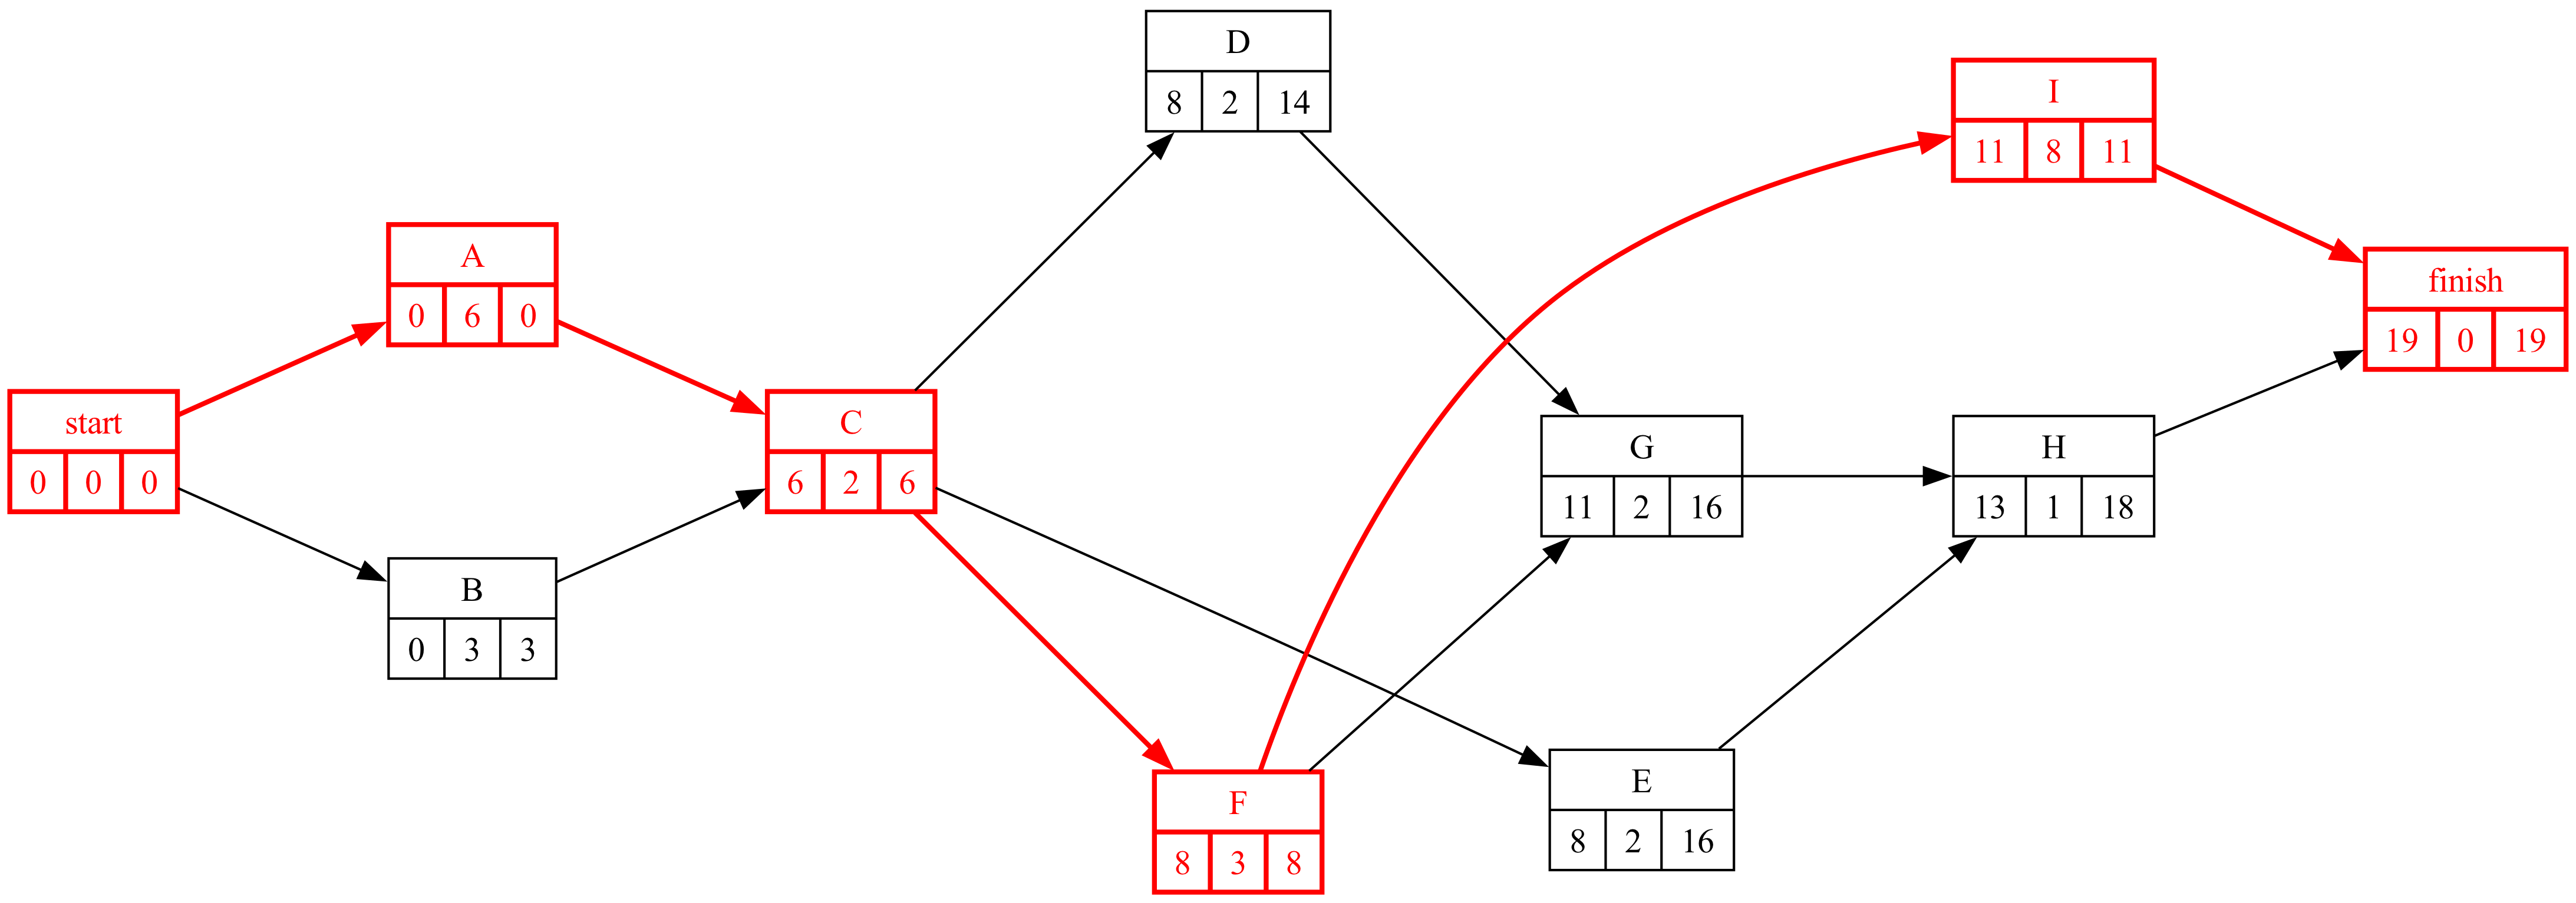

In [8]:
#| fig-cap: "Grafo Roy con las duraciones del plan"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Con el calendario de inicios más tempranos, identifique qué actividades afectadas terminan antes de la ventana y cuáles la ocupan (semanas dentro de la ventana) y, para estas, la espera necesaria para empezar después del 31 de mayo y si cabe en su holgura total. Obtenga el cronograma con las esperas (recalculando el calendario después de cada una) y la duración del proyecto.  

In [10]:
#| tbl-cap: "Actividades afectadas: fechas más tempranas, semanas en la ventana y espera necesaria"
#| label: tbl-ventana
tabla = calendario.loc[afectadas, ['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']].copy()
tabla['semanas en la ventana'] = [semanas_en_ventana(int(r['inicio_mas_temprano']), int(datos_proyecto.loc[a, 'duration'])) for a, r in tabla.iterrows()]
tabla['espera para empezar en la semana ' + str(ventana[1] + 1)] = [max(0, ventana[1] - int(r['inicio_mas_temprano'])) if r['semanas en la ventana'] > 0 else 0 for a, r in tabla.iterrows()]
tabla['cabe en la holgura'] = tabla.iloc[:, -1] <= tabla['H_total']
tabla

,inicio_mas_temprano,fin_mas_temprano,H_total,semanas en la ventana,espera para empezar en la semana 23,cabe en la holgura
activity,,,,,,
A,0,6,0,0,0,True
E,8,10,8,2,14,False
G,11,13,5,2,11,False


In [11]:
#| tbl-cap: "Esperas del plan (recalculando el calendario tras cada una)"
#| label: tbl-esperas
espera = pd.Series(0, index=datos_proyecto.index, dtype=int)
for _ in range(60):
    cal = proyecto.calendar(datos_proyecto['duration'] + espera)
    cambio = False
    for a in sorted(afectadas, key=lambda x: (int(cal.loc[x, 'inicio_mas_temprano']), x)):
        es, d = int(cal.loc[a, 'inicio_mas_temprano']), int(datos_proyecto.loc[a, 'duration'])
        nueva = 0 if es + d <= ventana[0] - 1 else max(0, ventana[1] - es)
        if nueva != int(espera[a]):
            espera[a] = nueva; cambio = True
            break
    if not cambio:
        break
duraciones_dia = datos_proyecto['duration'] + espera
calendario_dia = proyecto.calendar(duraciones_dia)
duracion_dia = int(proyecto.duration(duraciones_dia))
resumen = pd.DataFrame({'espera (semanas)': espera[afectadas], 'inicio real': calendario_dia.loc[afectadas, 'inicio_mas_temprano'] + espera[afectadas],
                        'fin': calendario_dia.loc[afectadas, 'fin_mas_temprano']})
display(resumen)
antes = [a for a in afectadas if espera[a] == 0 and semanas_en_ventana(int(calendario.loc[a, 'inicio_mas_temprano']), int(datos_proyecto.loc[a, 'duration'])) == 0]
Markdown(f'''Terminan antes de la ventana: {', '.join(antes)}. Esperan hasta la semana {ventana[1] + 1}: {', '.join(a for a in afectadas if espera[a] > 0)}. Con las esperas el proyecto dura **{duracion_dia}** semanas frente a {duracion} del plan.''')

,espera (semanas),inicio real,fin
activity,,,
A,0,0,6
E,14,22,24
G,11,22,24


Terminan antes de la ventana: A. Esperan hasta la semana 23: E, G. Con las esperas el proyecto dura **25** semanas frente a 19 del plan.

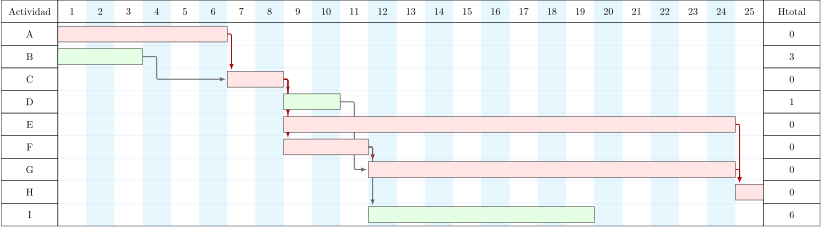

In [12]:
#| fig-cap: "Gantt del plan con las esperas (la barra incluye la espera de cada actividad afectada)"
#| label: fig-ganttDia
datos_dia = datos_proyecto.copy(); datos_dia['duration'] = duraciones_dia
_g, _dibujo = proyecto.copy().gantt(datos_dia, 'duration', holguras=True, tikz=True, params=dict(inner_text=None, **GANTT_PARAMS))
pinta_tikz(_dibujo)

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule el retraso y la penalidad del plan con esperas. Obtenga el adelanto mínimo del inicio del proyecto con el que ninguna actividad afectada tocaría la ventana, y el retraso mínimo del inicio con el mismo efecto, y compare los tres planes.  

In [14]:
#| tbl-cap: "Tres formas de respetar la ventana"
#| label: tbl-planes
retraso = duracion_dia - duracion
def inicio_valido(x):
    '''x > 0: el proyecto empieza x semanas antes; x < 0: después. ¿Ninguna afectada toca la ventana?'''
    for a in afectadas:
        es, ef = int(calendario.loc[a, 'inicio_mas_temprano']) - x, int(calendario.loc[a, 'fin_mas_temprano']) - x
        if not (ef <= ventana[0] - 1 or es >= ventana[1]):
            return False
    return True
adelanto = next(x for x in range(0, 60) if inicio_valido(x))
retraso_inicio = next(y for y in range(0, 60) if inicio_valido(-y))
planes = pd.DataFrame({'esperas selectivas': [duracion_dia, retraso, retraso * penalidad],
                       f'adelantar el inicio {adelanto} semanas': [duracion, -adelanto, 0],
                       f'retrasar el inicio {retraso_inicio} semanas': [duracion + retraso_inicio, retraso_inicio, retraso_inicio * penalidad]},
                      index=['fin respecto al inicio previsto (semana)', 'retraso de la entrega (semanas)', 'penalidad (k€)'])
display(planes)
Markdown(f'''Esperar sólo en las actividades afectadas retrasa la entrega **{retraso}** semanas ({retraso * penalidad} k€); empezar la obra {adelanto} semanas antes (si la autorización y el contrato lo permiten) la adelanta; empezar {retraso_inicio} semanas después, con todas las actividades afectadas tras la ventana, cuesta {retraso_inicio * penalidad} k€. Son los tres planes posibles; «hacerlo igual» no es el cuarto.''')

,esperas selectivas,adelantar el inicio 5 semanas,retrasar el inicio 22 semanas
fin respecto al inicio previsto (semana),25,19,41
retraso de la entrega (semanas),6,-5,22
penalidad (k€),72,0,264


Esperar sólo en las actividades afectadas retrasa la entrega **6** semanas (72 k€); empezar la obra 5 semanas antes (si la autorización y el contrato lo permiten) la adelanta; empezar 22 semanas después, con todas las actividades afectadas tras la ventana, cuesta 264 k€. Son los tres planes posibles; «hacerlo igual» no es el cuarto.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el desbroce dentro de la ventana «con un biólogo delante»? ¿Es la ventana una restricción del cronograma o un riesgo que se acepta? ¿Qué actividades deben reprogramarse?  

**Norma.** La ventana es una condición de la DIA incorporada a la autorización: ejecutar los trabajos dentro de ella es incumplir la condición (infracción grave, Ley 21/2013, art. 55.3.c) con independencia de que aparezca un nido; y si aparece, molestar a la fauna en reproducción o mover el nido está prohibido con o sin biólogo (Ley 42/2007, art. 54.5): el biólogo puede documentar el daño, no autorizarlo. **S12.** La ventana no tiene probabilidad, tiene fecha: es una **restricción del cronograma** (inicio no antes de la semana 23 o fin no después de la 8) de las actividades afectadas, no un riesgo que se acepta pagando 72 k€. Las actividades que deben reprogramarse las decide el calendario, no la opinión: con inicios más tempranos ocupan la ventana **E, G**; A terminan antes y no se tocan. «No está en el contrato con el cliente» es irrelevante: está en la autorización sin la cual no hay obra, y el cliente la conoce. **S11.** Lo que sí es un riesgo del proyecto es que el órgano ambiental amplíe la ventana, que un nido aparezca fuera de ella o que el tiempo retrase lo que debía terminar antes: eso entra en el registro con su probabilidad, su impacto y su respuesta (empezar antes, reordenar, reserva).

In [16]:
preguntas_test = [
    ('Una condición de la DIA que prohíbe determinadas actividades en una época del año es, para el cronograma…', ['una restricción de fecha de las actividades afectadas', 'un riesgo que se acepta si la penalidad lo compensa', 'una recomendación', 'una reserva de gestión'],
     'S12: tiene fecha, no probabilidad.'),
    ('Incumplir las condiciones ambientales establecidas en la declaración de impacto ambiental es…', ['infracción grave (Ley 21/2013, art. 55.3.c)', 'una irregularidad sin sanción', 'legal si lo supervisa un biólogo', 'sólo un incumplimiento contractual con el cliente'],
     'Art. 55.3.c) de la Ley 21/2013; además, Ley 42/2007, art. 54.5.'),
    ('Una actividad afectada que, con inicios más tempranos, ocupa semanas de la ventana retrasa el proyecto…', ['sólo si la espera necesaria supera su holgura total (y el calendario se recalcula)', 'siempre, tantas semanas como la espera', 'nunca', 'sólo si es inicial'],
     'Lección 05: la holgura total absorbe la espera; lo que sobra va al plazo.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — ventana ambiental')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — ventana ambiental

::Sostenibilidad 20 — ventana ambiental P1::Una condición de la DIA que prohíbe determinadas actividades en una época del año es, para el cronograma… {=una restricción de fecha de las actividades afectadas ~un riesgo que se acepta si la penalidad lo compensa ~una recomendación ~una reserva de gestión ####S12: tiene fecha, no probabilidad.}

::Sostenibilidad 20 — ventana ambiental P2::Incumplir las condiciones ambientales establecidas en la declaración de impacto ambiental es… {~sólo un incumplimiento contractual con el cliente =infracción grave (Ley 21/2013, art. 55.3.c) ~legal si lo supervisa un biólogo ~una irregularidad sin sanción ####Art. 55.3.c) de la Ley 21/2013; además, Ley 42/2007, art. 54.5.}

::Sostenibilidad 20 — ventana ambiental P3::Una actividad afectada que, con inicios más tempranos, ocupa semanas de la ventana retrasa el proyecto… {~sólo si es inicial =sólo si la espera necesaria supera su holgura total (y el calendari

## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de obra y qué comunica al cliente y al órgano ambiental? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de obra: la tabla del apartado 2; de los tres planes, el que menos cuesta y el que la autorización permite, y la lista de lo que sí se puede hacer dentro de la ventana (todo lo que no tiene afección: B, C, D, F, H, I). Al cliente: la condición de la DIA con su fecha, el plan elegido y su efecto en la entrega, y la petición de revisar la penalidad por una restricción que estaba en la autorización antes de firmar. Al órgano ambiental, si hace falta: la consulta sobre el calendario, no el hecho consumado. Prueba de publicidad: ¿explicaría al inspector del Seprona que el desbroce de abril «lo vigilaba un biólogo»?